# Summary

A qubit in state (|0> + |1>)/√2 isn't "secretly 0 or 1"

This experiment lets you view probability distribution over 100 runs given by the Born Rule (amplitude squared).

Build once as a vector and then as a qiskit circuit.

## Step 1 with NumPy:
### a) Define |0> as a column vector and the Hadamard Gate as a 2x2 matrix

In [1]:
pip install qiskit qiskit-aer matplotlib


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: /usr/local/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [33]:
from qiskit_aer import aer_simulator
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
import numpy as np

In [38]:
ket_0 = np.array([[1],
                  [0]], dtype=complex)
H = (1/np.sqrt(2)) * np.array([[1,  1],
                               [1, -1]], dtype=complex)

### b) Multiply then to get the state and square the amplitudes to get the predicted P(0) and P(1)

In [47]:
psi = H @ ket_0              # @ is matrix multiplication
probs = np.abs(psi)**2       # Born rule: |amplitude|^2
print(psi)                   # [[0.707+0j], [0.707+0j]]
print(probs)                 # [[0.5], [0.5]]

[[0.70710678+0.j]
 [0.70710678+0.j]]
[[0.5]
 [0.5]]


## Step 2 with Qiskit
### a) Build a one-qubit circuit with H and a measurement

In [25]:
from qiskit import QuantumCircuit
from qiskit import transpile

In [ ]:
qc = QuantumCircuit(1,1)
# first 1 is one qubit; every qubit starts as |0>
qc.h(0)
# applies H to qubit 0 (the equivalent of H @ ket_0 in the classical example)
print(Statevector(qc))
# dims(2,) lists the size of each substate. (2,) means two dimensional kets for basis state:
# |0> and |1> and the single number means just 1 qubit
qc.measure(0,0)
print(qc.draw())

Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))
     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


### b) Run it with Aer Simulator for 1000 shots

In [31]:
sim = AerSimulator()
compiled = transpile(qc,sim)
# transpile the quantum circuit and set up the simulator
job = sim.run(compiled, shots=1000)

### c) Plot a histogram of the counts

In [32]:
result = job.result()
counts = result.get_counts()
print(counts)

{'0': 517, '1': 483}


In [35]:
plot_histogram(counts)
plt.show()

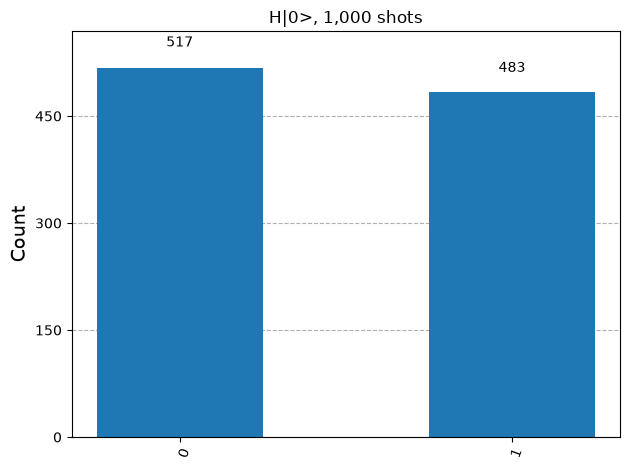

In [37]:
plot_histogram(counts, title="H|0>, 1,000 shots")

## Step 3 Comparison
### a) Print predicted and measured probabilities side by side

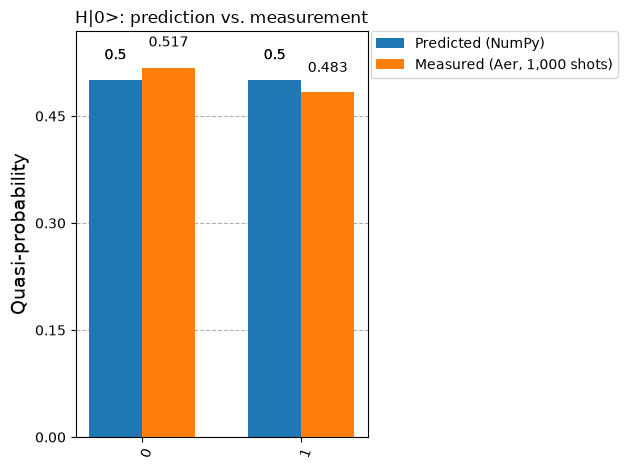

In [49]:
# Prediction from your NumPy step
predicted = (np.abs(H @ ket_0)**2).flatten()
predicted_probs = {'0': predicted[0].item(), '1': predicted[1].item()}

# Measurement from Aer: convert counts to fractions
shots = sum(counts.values())
measured_probs = {k: v / shots for k, v in counts.items()}

plot_histogram(
    [predicted_probs, measured_probs],
    legend=['Predicted (NumPy)', 'Measured (Aer, 1,000 shots)'],
    title='H|0>: prediction vs. measurement'
)

### b) Rerun with 10, 100, 1000, and 10000 shots and see how it looks

In [50]:
job10 = sim.run(compiled, shots=10)
job100 = sim.run(compiled, shots=100)
job1000 = sim.run(compiled, shots=1000)
job10000 = sim.run(compiled, shots=10000)

In [52]:
result10 = job10.result()
result100 = job100.result()
result1000 = job1000.result()
result10000 = job10000.result()

counts10 = result10.get_counts()
counts100 = result100.get_counts()
counts1000 = result1000.get_counts()
counts10000 = result10000.get_counts()

print(counts10)
print(counts100)
print(counts1000)
print(counts10000)

{'1': 3, '0': 7}
{'1': 53, '0': 47}
{'1': 518, '0': 482}
{'1': 5005, '0': 4995}


### c) At 1000 shots, deviation usually is plus or minus 16 counts. Error shrinks to 1/√N

In [20]:
exp_error = np.sqrt(.5 * .5 / 1000) * 1000
print("Expected deviation over 1000 simulations is", np.round(exp_error))

Expected deviation over 1000 simulations is 16.0
